# Tugas Kelompok 2: Penggabungan Dataset YouTube dan X — Program Makan Bergizi Gratis (MBG)

## Anggota Kelompok

1. Erland Hafizh Aristovi (2306165686)
2. Jasmine Rakhaila (2306165774)
3. Leonita Cecilia (2306165710)
4. Yeshua Marco Gracia Manurung (2306210286)

**Judul penelitian:** Analisis Kekhawatiran Publik terhadap Kebersihan dan Keamanan Pangan Program Makan Bergizi Gratis (MBG) pada Media Sosial YouTube dan X.

## Ringkasan Pipeline Penggabungan

Notebook ini adalah tahap terakhir *pipeline* pengumpulan data. Notebook ini menggabungkan hasil dua *pipeline* yang dijalankan terpisah:

| Sumber | File input | Dihasilkan oleh |
|---|---|---|
| YouTube | `data/interim/youtube/youtube_unified.csv` dan `run_metadata.json` | `youtube/TK2_YouTube_Pipeline.ipynb` (YouTube Data API v3) |
| X | `data/interim/x_unified.csv` dan `x_clean.csv` | `x/TK2_X_Scraping_Pipeline.ipynb` (*web scraping* Playwright) |

```
 youtube_unified.csv              x_unified.csv + x_clean.csv
          │                                  │
          └───────────────┬──────────────────┘
                          ▼
 [2] Muat data dan periksa skema (16 kolom skema bersama)
                          │
                          ▼
 [3] Harmonisasi: format waktu UTC, nama provinsi, kolom khusus platform
                          │
                          ▼
 [4] Flag yang sama untuk kedua platform:
     is_suspected_spam, is_repeated_text, mentions_mbg, mentions_food_safety, is_relevant_candidate
                          │
                          ▼
 [5] mbg_merged.csv + merge_metadata.json
                          │
                          ▼
 [6] EDA ringkas per platform
```

Notebook ini **tidak memanggil API** dan tidak membuang baris apa pun, sehingga dapat dijalankan ulang kapan saja setelah salah satu dataset diperbarui. Penyaringan (misalnya membuang spam atau memilih dokumen relevan) dilakukan pada tahap analisis memakai kolom flag.

# 1. Persiapan

## 1.1. Import Library

* `pandas` untuk memuat, menggabungkan, dan menyimpan data.
* `matplotlib` untuk visualisasi pada bagian EDA.
* `re` dan `unicodedata` untuk penanda spam dan pencocokan kata kunci.
* `json` untuk membaca dan menyimpan metadata.

In [23]:
import os
import re
import json
import unicodedata
from pathlib import Path
from datetime import datetime, timezone

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_colwidth", 80)

## 1.2. Lokasi File Input dan Output

Notebook dijalankan dari folder `merge/` (atau dari folder proyek). Input dibaca dari `data/interim/` (hasil *pipeline* YouTube di subfolder `youtube/`, hasil *pipeline* X langsung di `data/interim/`). Hasil penggabungan disimpan di `data/processed/raw_merged/`, yang menjadi input notebook *pre-processing* per RQ.

In [24]:
BASE_DIR = Path.cwd().parent if Path.cwd().name == "merge" else Path.cwd()
YOUTUBE_DIR = BASE_DIR / "data" / "interim" / "youtube"
X_DIR = BASE_DIR / "data" / "interim"
OUTPUT_DIR = BASE_DIR / "data" / "processed" / "raw_merged"
FIGURE_DIR = BASE_DIR / "merge" / "figures"

INPUT_FILES = {
    "youtube_unified": YOUTUBE_DIR / "youtube_unified.csv",
    "youtube_metadata": YOUTUBE_DIR / "run_metadata.json",
    "x_unified": X_DIR / "x_unified.csv",
    "x_clean": X_DIR / "x_clean.csv",
}
missing_files = [f"{name}: {path}" for name, path in INPUT_FILES.items() if not path.exists()]
assert not missing_files, "File input belum ada:\n" + "\n".join(missing_files)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
print("Folder proyek:", BASE_DIR)
print("Folder output:", OUTPUT_DIR)

Folder proyek: z:\Universitas Indonesia\Semester 7\Anmedsos\Tugas\TK2\Youtube\FINAL\MAIN
Folder output: z:\Universitas Indonesia\Semester 7\Anmedsos\Tugas\TK2\Youtube\FINAL\MAIN\data\processed\raw_merged


## 1.3. Fungsi Helper

* `save_csv()`: menulis ke file sementara lalu menggantinya, agar file tidak rusak jika notebook terhenti saat menulis.
* `save_figure()`: menyimpan grafik ke `merge/figures/`.
* `PLATFORM_COLORS`: warna tetap per platform di semua grafik (YouTube biru, X oranye).

In [25]:
def save_csv(df, path):
    tmp_path = Path(str(path) + ".tmp")
    df.to_csv(tmp_path, index=False, encoding="utf-8")
    tmp_path.replace(path)


def save_figure(name):
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f"{name}.png", dpi=150)
    plt.show()


PLATFORM_COLORS = {"youtube": "#2a78d6", "x": "#eb6834"}
PLATFORMS = ["youtube", "x"]

# 2. Memuat dan Memeriksa Data

## 2.1. Dataset YouTube

Memuat `youtube_unified.csv` (video, comment, dan reply dalam satu tabel) beserta `run_metadata.json`. Metadata dipakai untuk mengecek apakah pengumpulan YouTube sudah lengkap (`collection_complete`). Semua kolom dibaca sebagai teks agar ID dan tanggal tidak berubah bentuk.

In [26]:
youtube = pd.read_csv(INPUT_FILES["youtube_unified"], dtype=str, keep_default_na=False)
youtube_meta = json.loads(INPUT_FILES["youtube_metadata"].read_text(encoding="utf-8"))

print("youtube_unified:", youtube.shape, youtube["doc_type"].value_counts().to_dict())
print("Dataset YouTube dibuat     :", youtube_meta["created_at_utc"])
print("Pengumpulan YouTube lengkap:", youtube_meta["collection_complete"])
if not youtube_meta["collection_complete"]:
    print("\nPERINGATAN: pengumpulan YouTube belum lengkap. Hasil penggabungan ini bersifat sementara;"
          "\njalankan ulang notebook ini setelah notebook YouTube berstatus LENGKAP.")

youtube_unified: (1085353, 17) {'comment': 892141, 'reply': 175549, 'video': 17663}
Dataset YouTube dibuat     : 2026-10-24T09:26:12.745631+00:00
Pengumpulan YouTube lengkap: True


## 2.2. Dataset X

Memuat `x_unified.csv` (post, reply, dan quote yang sudah dipetakan ke skema bersama). Dari `x_clean.csv` hanya diambil tiga kolom:

* `collected_at`: waktu pengambilan data, untuk mengisi kolom `collected_at_utc` yang tidak ada di `x_unified.csv`;
* `is_repeated_text` dan `is_relevant_candidate`: flag versi *pipeline* X, hanya untuk dibandingkan dengan flag yang dihitung ulang di bagian 4.

In [27]:
x_unified = pd.read_csv(INPUT_FILES["x_unified"], dtype=str, keep_default_na=False)
x_clean = pd.read_csv(INPUT_FILES["x_clean"], dtype=str, keep_default_na=False,
                      usecols=["post_id", "collected_at", "is_repeated_text", "is_relevant_candidate"])
x_clean["doc_id"] = "x_" + x_clean["post_id"]

assert x_clean["doc_id"].is_unique and set(x_clean["doc_id"]) == set(x_unified["doc_id"]), \
    "x_clean.csv dan x_unified.csv tidak berisi unggahan yang sama"
print("x_unified:", x_unified.shape, x_unified["doc_type"].value_counts().to_dict())

x_unified: (24535, 17) {'post': 13985, 'reply': 8069, 'quote': 2481}


## 2.3. Pemeriksaan Skema

Kedua *pipeline* sudah memakai **16 kolom skema bersama** yang disepakati kelompok. Selain itu, masing-masing platform memiliki satu kolom tambahan:

* `collected_at_utc` (YouTube): waktu pengambilan data. Untuk X, kolom ini diisi dari `x_clean.csv`.
* `quoted_doc_id` (X): unggahan yang dikutip oleh sebuah *quote*. Untuk YouTube, kolom ini kosong karena YouTube tidak memiliki fitur kutipan.

In [28]:
SHARED_COLUMNS = ["doc_id", "platform", "doc_type", "parent_doc_id", "context_id", "source_name",
                  "source_category", "author_hash", "text_raw", "text_clean", "published_at_utc",
                  "like_count", "reply_count", "url", "location_names", "province"]
EXTRA_COLUMNS = ["collected_at_utc", "quoted_doc_id"]

all_columns = SHARED_COLUMNS + EXTRA_COLUMNS
schema = pd.DataFrame({"youtube": [c in youtube.columns for c in all_columns],
                       "x": [c in x_unified.columns for c in all_columns]}, index=all_columns)
display(schema.T)
assert schema.loc[SHARED_COLUMNS].all().all(), "Ada kolom skema bersama yang hilang"

,doc_id,platform,doc_type,parent_doc_id,context_id,source_name,source_category,author_hash,text_raw,text_clean,published_at_utc,like_count,reply_count,url,location_names,province,collected_at_utc,quoted_doc_id
youtube,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,False
x,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,False,True


In [29]:
# Contoh nilai yang formatnya berbeda antarplatform.
example_doc = pd.DataFrame({
    "youtube": youtube[["doc_id", "doc_type", "published_at_utc", "province"]].iloc[0],
    "x": x_unified[["doc_id", "doc_type", "published_at_utc", "province"]].iloc[0],
})
display(example_doc)

,youtube,x
doc_id,yt_v_XEnNRIJRCds,x_1874364094129881562
doc_type,video,post
published_at_utc,2025-03-28 12:31:53+00:00,2025-01-01T07:56:38Z
province,DKI Jakarta; Jawa Tengah,Jambi


# 3. Harmonisasi

Perbedaan yang ditemukan di bagian 2.3 dan cara penanganannya:

| Perbedaan | YouTube | X | Penanganan |
|---|---|---|---|
| Format waktu | `2025-03-28 12:31:53+00:00` | `2025-01-01T07:56:38Z` | Keduanya diubah ke ISO 8601 UTC: `2025-03-28T12:31:53Z` |
| Nama provinsi DIY | `Daerah Istimewa Yogyakarta` | `DI Yogyakarta` | Diseragamkan ke nama resmi `Daerah Istimewa Yogyakarta` |
| `collected_at_utc` | Ada | Hanya di `x_clean.csv` | Diambil dari `x_clean.collected_at` |
| `quoted_doc_id` | Tidak ada | Ada | Dipertahankan; kosong untuk YouTube |
| Jenis dokumen (`doc_type`) | `video`, `comment`, `reply` | `post`, `reply`, `quote` | Dipertahankan; arti tiap jenis dijelaskan di bagian 5.2 |
| Flag kualitas dan relevansi | Spam dan teks berulang hanya di `comments_clean.csv` | Teks berulang dan relevansi hanya di `x_clean.csv` | Dihitung ulang untuk kedua platform dengan definisi yang sama (bagian 4) |

## 3.1. Format Waktu dan Nama Provinsi

In [30]:
def to_iso_utc(values):
    # "2025-03-28 12:31:53+00:00" dan "2025-01-01T07:56:38Z" -> "2025-03-28T12:31:53Z"; nilai kosong tetap kosong.
    converted = pd.to_datetime(values, utc=True, format="mixed", errors="coerce")
    unreadable = converted.isna() & (values != "")
    assert not unreadable.any(), f"Ada {int(unreadable.sum())} tanggal yang tidak terbaca"
    return converted.dt.strftime("%Y-%m-%dT%H:%M:%SZ").fillna("")


PROVINCE_NAMES = {"DI Yogyakarta": "Daerah Istimewa Yogyakarta"}


def harmonize_names(values):
    # Nilai berisi beberapa nama yang dipisah "; ", misalnya "DI Yogyakarta; Jawa Tengah".
    return values.map(lambda text: "; ".join(PROVINCE_NAMES.get(name, name) for name in text.split("; ")) if text else "")


x_unified["collected_at_utc"] = x_unified["doc_id"].map(x_clean.set_index("doc_id")["collected_at"])
youtube["quoted_doc_id"] = ""

for df in [youtube, x_unified]:
    for column in ["published_at_utc", "collected_at_utc"]:
        df[column] = to_iso_utc(df[column])
    for column in ["location_names", "province"]:
        df[column] = harmonize_names(df[column])

for name, df in [("youtube", youtube), ("x", x_unified)]:
    published = pd.to_datetime(df["published_at_utc"])
    print(f"{name:8s} terbit {published.min()} s.d. {published.max()} | contoh: {df['published_at_utc'].iloc[0]}")

youtube  terbit 2025-01-05 22:34:42+00:00 s.d. 2026-10-24 00:55:09+00:00 | contoh: 2025-03-28T12:31:53Z
x        terbit 2025-01-01 07:56:38+00:00 s.d. 2026-09-29 23:02:39+00:00 | contoh: 2025-01-01T07:56:38Z


## 3.2. Menggabungkan Kedua Dataset

In [31]:
MERGED_COLUMNS = SHARED_COLUMNS + EXTRA_COLUMNS
merged = pd.concat([youtube[MERGED_COLUMNS], x_unified[MERGED_COLUMNS]], ignore_index=True)
merged["like_count"] = pd.to_numeric(merged["like_count"]).astype("Int64")
merged["reply_count"] = pd.to_numeric(merged["reply_count"].mask(merged["reply_count"] == "")).astype("Int64")

print("Dataset gabungan:", merged.shape)
display(merged.groupby(["platform", "doc_type"]).size().rename("n_docs").to_frame())

Dataset gabungan: (1109888, 18)


n_docs
platform doc_type        
x        post       13985
         quote       2481
         reply       8069
youtube  comment   892141
         reply     175549
         video      17663

## 3.3. Validasi Dataset Gabungan

Pemeriksaan otomatis sebelum flag dihitung. Untuk YouTube, setiap comment/reply wajib memiliki induk di dataset. Untuk X, induk sebuah reply bisa berada di luar dataset (unggahan induk tidak cocok dengan query pencarian), sehingga hanya dilaporkan jumlahnya.

In [32]:
doc_types = {"youtube": {"video", "comment", "reply"}, "x": {"post", "reply", "quote"}}
provinces = {name for text in merged["province"] for name in text.split("; ") if name}
is_youtube = merged["platform"] == "youtube"
youtube_children = is_youtube & (merged["doc_type"] != "video")
x_replies = (merged["platform"] == "x") & (merged["doc_type"] == "reply") & (merged["parent_doc_id"] != "")

checks = {
    "doc_id unik di seluruh dataset gabungan": merged["doc_id"].is_unique,
    "platform hanya youtube/x": set(merged["platform"]) == set(PLATFORMS),
    "doc_type sesuai platform": all(set(merged.loc[merged["platform"] == p, "doc_type"]) <= t for p, t in doc_types.items()),
    "published_at_utc berformat ISO 8601 UTC": merged["published_at_utc"].str.fullmatch(r"\d{4}-\d{2}-\d{2}T\d{2}:\d{2}:\d{2}Z").all(),
    "nama provinsi seragam (maks. 38, tanpa 'DI Yogyakarta')": len(provinces) <= 38 and "DI Yogyakarta" not in provinces,
    "text_clean tidak kosong": (merged["text_clean"].str.len() > 0).all(),
    "like_count tidak negatif": (merged["like_count"] >= 0).all(),
    "induk comment/reply YouTube ada di dataset": merged.loc[youtube_children, "parent_doc_id"].isin(merged["doc_id"]).all(),
}
for name, ok in checks.items():
    print("PASS" if ok else "FAIL", "-", name)
assert all(checks.values()), "Validasi dataset gabungan gagal"

print(f"\nReply X dengan induk di dataset: {int(merged.loc[x_replies, 'parent_doc_id'].isin(merged['doc_id']).sum())} "
      f"dari {int(x_replies.sum())} (sisanya induk di luar dataset)")

PASS - doc_id unik di seluruh dataset gabungan
PASS - platform hanya youtube/x
PASS - doc_type sesuai platform
PASS - published_at_utc berformat ISO 8601 UTC
PASS - nama provinsi seragam (maks. 38, tanpa 'DI Yogyakarta')
PASS - text_clean tidak kosong
PASS - like_count tidak negatif
PASS - induk comment/reply YouTube ada di dataset

Reply X dengan induk di dataset: 1097 dari 7895 (sisanya induk di luar dataset)


# 4. Flag Kualitas Data dan Relevansi

Semua flag dihitung ulang pada dataset gabungan memakai **definisi yang sama untuk kedua platform**, sehingga persentasenya dapat dibandingkan. Tidak ada baris yang dibuang; flag dipakai untuk menyaring data pada tahap analisis.

| Kolom | Arti | Asal definisi |
|---|---|---|
| `is_suspected_spam` | Promosi judi online, termasuk yang disamarkan | *Pipeline* YouTube (bagian 2.1) |
| `is_repeated_text` | Teks identik muncul lebih dari sekali di platform yang sama | Disamakan dari kedua *pipeline* |
| `mentions_mbg` | Teks menyebut MBG, SPPG, BGN, dan sejenisnya | *Pipeline* X (bagian 3.10) |
| `mentions_food_safety` | Teks menyebut masalah keamanan/kebersihan pangan | *Pipeline* X (bagian 3.10) |
| `context_mentions_mbg` | Dokumen akar percakapan (video atau post awal) menyebut MBG | Baru, lihat 4.3 |
| `is_relevant_candidate` | Kandidat dokumen relevan untuk RQ (keamanan pangan MBG) | Lihat 4.3 |

## 4.1. Penanda Spam Judi Online (`is_suspected_spam`)

Memakai fungsi yang sama dengan *pipeline* YouTube. Spam judi menyamarkan nama situs dengan huruf berspasi ("B A N T E N G H O K I"), font Unicode mewah ("𝑻𝑶𝑻𝑶𝟑𝟐𝟖"), huruf Cyrillic, atau angka 0 sebagai huruf o. Teks dinormalisasi terlebih dahulu, lalu ditandai jika memenuhi salah satu aturan:

1. memuat nama situs judi yang ditemukan di data (`GAMBLING_SITES`);
2. memuat kata yang disamarkan berisi akar kata judi atau berpola nama situs huruf + 2–3 angka;
3. memuat akar kata judi dengan akhiran angka ("pstoto99");
4. memuat kata judi dan kata promosi tanpa kata kritik.

Video YouTube tidak diperiksa karena berasal dari channel media/BGN yang sudah diverifikasi; deskripsi berita dapat memuat kata seperti "depo" (Depo Pertamina) dan tautan sehingga rawan salah tangkap. Daftar nama situs disusun dari spam di comment YouTube, sehingga sampel X yang ditandai ditampilkan di bawah untuk diperiksa manual.

In [33]:
# Huruf Cyrillic dan huruf kapital kecil yang mirip huruf Latin (tidak diubah oleh NFKC).
LOOKALIKE = str.maketrans("АВЕКМНОРСТХУаеорсухіІЯяᴀʙᴄᴅᴇɢʜɪᴊᴋʟᴍɴᴏᴘʀᴛᴜᴡʏᴢ",
                          "abekmhopctxyaeopcyxiirrabcdeghijklmnoprtuwyz")
# Nama situs judi yang ditemukan di comment dataset YouTube (dicocokkan setelah spasi dan tanda baca dihapus).
GAMBLING_SITES = ["bantenghok", "garudahok", "jptogel", "manjurbet", "agustoto", "pstoto", "probet", "koislot",
                  "dewadora", "visi4d", "toto328", "cuan328", "suhu328", "macau328", "miya88", "win303", "alexis17"]
GAMBLING_ROOT = r"(?:hoki|gacor|slot|toto|togel|maxwin|casino|judi)"
GAMBLING_WORDS = r"\b(slot|casino|togel|maxwin|gacor|jackpot|jakpot|scatter|jepe|depo)\b"
PROMOTION_WORDS = r"\b(daftar|bonus|link|situs|gabung|join|hubungi|wa|saldo|wd)\b|https?://"
CRITICISM_WORDS = r"\b(jangan|stop|bahaya|haram|tolak|berantas|hindari|waspada|meresahkan|tertibkan|blokir|tangkap)\b"


def to_plain(text):
    # Font mewah, huruf lebar, Cyrillic, dan kapital kecil -> huruf Latin biasa: "𝑻𝑶𝑻𝑶𝟑𝟐𝟖" -> "toto328".
    return unicodedata.normalize("NFKC", text).translate(LOOKALIKE).lower()


def is_disguised_gambling_word(word):
    # Kata samaran berisi akar kata judi ("koisl0t") atau berpola nama situs huruf + angka ("dora77").
    word = re.sub(r"[^a-z0-9]", "", to_plain(word))
    return bool(re.search(GAMBLING_ROOT, word.replace("0", "o")) or re.fullmatch(r"[a-z]{3,}\d{2,3}", word))


def is_suspected_spam(text):
    text = re.sub(r"@\S+", " ", text)  # nama akun yang di-mention bukan isi teks
    plain = to_plain(text)
    # 1) Nama situs judi yang dikenal, walaupun dieja berspasi atau memakai angka 0 sebagai huruf o.
    joined = re.sub(r"[^a-z0-9]", "", plain)
    if any(site in joined or site in joined.replace("0", "o") for site in GAMBLING_SITES):
        return True
    # 2) Kata yang sengaja disamarkan dengan huruf berspasi atau font mewah.
    spaced = re.findall(r"\b(?:[A-Za-z0-9] ){3,}[A-Za-z0-9]\b", text)
    # Hanya huruf yang dihitung: angka superscript dipakai sebagai tanda ulang ("anak²") pada teks biasa.
    fancy = [w for w in text.split() if any(not ch.isascii() and ch.isalpha() and to_plain(ch).isascii() for ch in w)]
    if any(is_disguised_gambling_word(word) for word in spaced + fancy):
        return True
    # 3) Akar kata judi dengan akhiran angka tanpa penyamaran ("pstoto99").
    if re.search(rf"\b[a-z]*{GAMBLING_ROOT}[a-z]*\d{{2,3}}\b", plain):
        return True
    # 4) Kata judi + kata promosi, kecuali jika teks mengkritik judi.
    return bool(re.search(GAMBLING_WORDS, plain) and re.search(PROMOTION_WORDS, plain)
                and not re.search(CRITICISM_WORDS, plain))


# Video berasal dari channel media/BGN terverifikasi, sehingga hanya comment, reply, dan unggahan X yang diperiksa.
merged["is_suspected_spam"] = (merged["doc_type"] != "video") & merged["text_clean"].map(is_suspected_spam)
print("Dokumen dicurigai spam per platform:", merged.groupby("platform")["is_suspected_spam"].sum().to_dict())

Dokumen dicurigai spam per platform: {'x': 0, 'youtube': 2357}


In [34]:
x_spam = merged[(merged["platform"] == "x") & merged["is_suspected_spam"]]
if len(x_spam):
    display(x_spam.sample(min(15, len(x_spam)), random_state=42)[["doc_id", "text_clean"]])
else:
    print("Tidak ada unggahan X yang ditandai spam.")

Tidak ada unggahan X yang ditandai spam.


## 4.2. Teks Berulang (`is_repeated_text`)

Kedua *pipeline* menandai teks yang identik, tetapi dengan aturan sedikit berbeda: YouTube mengabaikan huruf besar/kecil, sedangkan X membedakannya. Di sini dipakai satu aturan: teks dianggap sama jika identik setelah diubah ke huruf kecil. Pengecekan dilakukan **per platform**, agar slogan seperti "stop mbg" di YouTube tidak ikut ditandai hanya karena juga muncul di X. Semua anggota grup ditandai (termasuk kemunculan pertama), dan tidak ada yang dihapus, karena teks berulang bisa berupa slogan organik maupun kampanye terkoordinasi. Video YouTube ikut diperiksa, sehingga video yang diunggah ulang dengan judul dan deskripsi identik juga ditandai.

In [35]:
repeat_key = merged["text_clean"].str.lower()
merged["is_repeated_text"] = pd.DataFrame({"platform": merged["platform"], "key": repeat_key}).duplicated(keep=False)

print("Dokumen teks berulang per platform:", merged.groupby("platform")["is_repeated_text"].sum().to_dict())
for platform in PLATFORMS:
    top_repeated = (repeat_key[(merged["platform"] == platform) & merged["is_repeated_text"]]
                    .value_counts().head(8).rename("n_occurrences").to_frame())
    print(f"\nTeks berulang terbanyak - {platform}:")
    display(top_repeated)

Dokumen teks berulang per platform: {'x': 1012, 'youtube': 69737}

Teks berulang terbanyak - youtube:


,n_occurrences
text_clean,
stop mbg,1357
setuju,874
😂😂😂,851
😂,718
mantap,671
betul,529
bubarkan mbg,508
😂😂😂😂,487



Teks berulang terbanyak - x:


,n_occurrences
text_clean,
keracunan mbg,12
"kandungan gizi belalang dan ulat sagu, serangga yang berpotensi jadi menu mbg https://www.inews.id/lifestyle/health/kandungan-gizi-belalang-dan-ulat-sagu-serangga-yang-berpotensi-jadi-menu-mbg",11
kata istana soal puluhan siswa sd di sukoharjo diduga keracunan usai santap mbg https://www.inews.id/news/nasional/kata-istana-soal-puluhan-siswa-sd-di-sukoharjo-diduga-keracunan-usai-santap-mbg,9
"perbaikan program makan bergizi gratis adalah langkah nyata memastikan anak-anak indonesia memperoleh gizi terbaik untuk masa depan yang lebih kuat, sehat, dan berprestasi. #makanbergizigratis #mbg #gizianakindonesia #generasiemasindonesia",8
"evaluasi program makan bergizi gratis menjadi bukti keseriusan presiden prabowo dalam memastikan program berjalan transparan, akuntabel, dan tepat sasaran #makanbergizigratis #mbg #prabowosubianto #programprioritas",7
"makan bergizi gratis bukan sekadar program, tapi investasi masa depan dari piring anak-anak hari ini, lahir sdm unggul, ekonomi kuat, dan indonesia emas 2045 #makanbergizigratis #investasimasadepan #sdmunggul #ekonomikuat #indonesiaemas2045",6
"sppg polri pejaten menghadirkan inovasi penyaluran makan bergizi gratis (mbg) melalui sistem prasmanan yang perdana diterapkan di sma kemala bhayangkari 1 pasar minggu, rabu (22/4). polri terus berkomitmen #menjagaketahananpangan serta mendukung program gizi untuk indonesia",6
"penataan mbg melalui evaluasi dan penajaman sasaran menunjukkan komitmen pemerintah untuk memastikan program lebih efektif, tepat sasaran, dan berkelanjutan. #makanbergizigratis #mbg #programtepatsasaran #pemerintahbekerja #indonesiamaju",6


## 4.3. Flag Relevansi (`mentions_mbg`, `mentions_food_safety`, `is_relevant_candidate`)

Kamus kata kunci MBG (`RE_MBG`) dan keamanan pangan (`RE_PANGAN`) diambil dari *pipeline* X agar definisinya sama.

Pada *pipeline* X, sebuah unggahan dianggap kandidat relevan jika teksnya sendiri menyebut MBG **dan** masalah keamanan pangan. Aturan ini terlalu ketat untuk comment YouTube: comment seperti *"anak saya juga muntah setelah makan siang di sekolah"* di bawah video keracunan MBG jelas relevan, tetapi tidak menyebut kata "MBG" karena konteksnya sudah jelas dari video. Karena itu, aturan relevansi diperluas dengan konteks percakapan:

* `context_mentions_mbg`: dokumen akar percakapan (`context_id`), yaitu video untuk comment YouTube dan post awal untuk reply X, menyebut MBG;
* `is_relevant_candidate` = `mentions_food_safety` **dan** (`mentions_mbg` **atau** `context_mentions_mbg`).

Flag ini adalah **kandidat** berbasis kata kunci, bukan klasifikasi akhir. Pemilihan dokumen akhir dapat disempurnakan pada tahap analisis (TK4).

In [36]:
RE_MBG = re.compile(
    r"mbg|makan\s+(?:bergizi|siang)\s+gratis|makan\s+gratis|\bsppg\b|\bbgn\b|badan\s+gizi\s+nasional|pemenuhan\s+gizi",
    re.IGNORECASE,
)
RE_PANGAN = re.compile(
    r"racun|(?<!\w)(?:ber|ter|ke|di|me|meng)?(?:basi|busuk|bau|lendir|bakteri|kontaminasi|salmonella|e\.?\s?coli|belatung|ulat|kecoa|serangga"
    r"|benda\s+asing|rambut|plastik|higien\w*|kebersihan|sanitasi|kotor|jorok|mentah|hambar|(?:tidak|belum|kurang)\s+matang"
    r"|tidak\s+layak|layak\s+konsumsi|kedaluwarsa|kadaluarsa|kadaluwarsa|muntah|mual|diare|sakit\s+perut|rawat\s+inap|opname|alergi|steril\w*)(?:nya|an|kan|i)?(?!\w)",
    re.IGNORECASE,
)

merged["mentions_mbg"] = merged["text_clean"].str.contains(RE_MBG)
merged["mentions_food_safety"] = merged["text_clean"].str.contains(RE_PANGAN)
merged["context_mentions_mbg"] = merged["context_id"].map(merged.set_index("doc_id")["mentions_mbg"]).fillna(False).astype(bool)
merged["is_relevant_candidate"] = merged["mentions_food_safety"] & (merged["mentions_mbg"] | merged["context_mentions_mbg"])

relevance_flags = ["mentions_mbg", "mentions_food_safety", "context_mentions_mbg", "is_relevant_candidate"]
display(merged.groupby("platform")[relevance_flags].sum())

,mentions_mbg,mentions_food_safety,context_mentions_mbg,is_relevant_candidate
platform,,,,
x,24187,14833,17435,14731
youtube,288895,88383,1082877,88135


## 4.4. Perbandingan dengan Flag Asli *Pipeline* X

Membandingkan flag X hasil hitung ulang dengan flag asli dari `x_clean.csv`, agar perbedaannya terdokumentasi:

* `is_repeated_text` bisa bertambah karena huruf besar/kecil kini diabaikan;
* `is_relevant_candidate` bisa bertambah karena reply yang post awalnya menyebut MBG kini ikut dihitung.

In [37]:
x_merged = merged[merged["platform"] == "x"].set_index("doc_id")
x_original = x_clean.set_index("doc_id").loc[x_merged.index]

flag_comparison = pd.DataFrame([
    {"flag": flag,
     "pipeline_x": int((x_original[flag] == "True").sum()),
     "dataset_gabungan": int(x_merged[flag].sum()),
     "hanya_di_gabungan": int((x_merged[flag] & (x_original[flag] != "True")).sum()),
     "hanya_di_pipeline_x": int((~x_merged[flag] & (x_original[flag] == "True")).sum())}
    for flag in ["is_repeated_text", "is_relevant_candidate"]
])
display(flag_comparison)

,flag,pipeline_x,dataset_gabungan,hanya_di_gabungan,hanya_di_pipeline_x
0,is_repeated_text,1003,1012,9,0
1,is_relevant_candidate,14723,14731,8,0


# 5. Penyimpanan Dataset Gabungan

## 5.1. Dataset dan Metadata

Menyimpan dua file ke `data/processed/raw_merged/`:

| File | Isi |
|---|---|
| `mbg_merged.csv` | Seluruh dokumen YouTube dan X (tidak ada yang dibuang) beserta flag |
| `merge_metadata.json` | Waktu penggabungan, file input, status kelengkapan YouTube, jumlah baris, dan jumlah flag per platform |

In [38]:
FLAG_COLUMNS = ["is_suspected_spam", "is_repeated_text"] + relevance_flags
FINAL_COLUMNS = MERGED_COLUMNS + FLAG_COLUMNS
save_csv(merged[FINAL_COLUMNS], OUTPUT_DIR / "mbg_merged.csv")

merge_metadata = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "input_files": {name: Path(os.path.relpath(path, BASE_DIR)).as_posix() for name, path in INPUT_FILES.items()},
    "youtube_collection_complete": youtube_meta["collection_complete"],
    "youtube_dataset_created_at_utc": youtube_meta["created_at_utc"],
    "rows": merged.groupby("platform").size().to_dict() | {"total": len(merged)},
    "doc_types": {p: merged.loc[merged["platform"] == p, "doc_type"].value_counts().to_dict() for p in PLATFORMS},
    "flags": {flag: merged.groupby("platform")[flag].sum().astype(int).to_dict() for flag in FLAG_COLUMNS},
    "province_renamed": PROVINCE_NAMES,
    "re_mbg": RE_MBG.pattern,
    "re_pangan": RE_PANGAN.pattern,
}
(OUTPUT_DIR / "merge_metadata.json").write_text(json.dumps(merge_metadata, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"mbg_merged.csv: {len(merged)} baris x {len(FINAL_COLUMNS)} kolom")
print(json.dumps({k: merge_metadata[k] for k in ["rows", "flags"]}, indent=2))

mbg_merged.csv: 1109888 baris x 24 kolom
{
  "rows": {
    "x": 24535,
    "youtube": 1085353,
    "total": 1109888
  },
  "flags": {
    "is_suspected_spam": {
      "x": 0,
      "youtube": 2357
    },
    "is_repeated_text": {
      "x": 1012,
      "youtube": 69737
    },
    "mentions_mbg": {
      "x": 24187,
      "youtube": 288895
    },
    "mentions_food_safety": {
      "x": 14833,
      "youtube": 88383
    },
    "context_mentions_mbg": {
      "x": 17435,
      "youtube": 1082877
    },
    "is_relevant_candidate": {
      "x": 14731,
      "youtube": 88135
    }
  }
}


## 5.2. Kamus Kolom `mbg_merged.csv`

| Kolom | Keterangan |
|---|---|
| `doc_id` | ID unik: `yt_v_<video_id>`, `yt_c_<comment_id>`, atau `x_<post_id>` |
| `platform` | `youtube` atau `x` |
| `doc_type` | YouTube: `video` (konten media/BGN), `comment`, `reply`. X: `post`, `reply`, `quote` (unggahan yang mengutip unggahan lain) |
| `parent_doc_id` | Induk langsung: video untuk comment, comment untuk reply YouTube; unggahan yang dibalas/dikutip di X |
| `context_id` | Akar percakapan: video (YouTube) atau post awal yang dapat ditelusuri (X) |
| `source_name`, `source_category` | Nama channel dan kategorinya (`national_media`/`government`); kosong untuk X |
| `author_hash` | Pseudonim penulis (SHA-256 dengan *salt* rahasia masing-masing *pipeline*); kosong untuk video |
| `text_raw`, `text_clean` | Teks asli dan teks yang sudah dirapikan (HTML, Unicode, spasi); URL, mention, emoji tidak diubah |
| `published_at_utc` | Waktu terbit, ISO 8601 UTC |
| `like_count`, `reply_count` | Jumlah *like* dan balasan menurut platform; untuk video, `reply_count` = jumlah comment |
| `url` | Tautan ke dokumen (tanpa *handle* akun untuk X) |
| `location_names`, `province` | Lokasi yang disebut dalam teks, hasil ekstraksi masing-masing *pipeline* |
| `collected_at_utc` | Waktu pengambilan data |
| `quoted_doc_id` | Unggahan yang dikutip (khusus X) |
| `is_suspected_spam` … `is_relevant_candidate` | Flag dari bagian 4 |

Hasil *hash* `author_hash` antarplatform **tidak dapat dicocokkan**, karena akun YouTube dan X berbeda dan *salt*-nya berbeda.

# 6. Exploratory Data Analysis Dataset Gabungan

## 6.1. Jumlah Dokumen per Platform dan Jenis

In [39]:
doc_summary = merged.groupby(["platform", "doc_type"]).agg(
    n_docs=("doc_id", "count"),
    n_authors=("author_hash", lambda s: s[s != ""].nunique()),
    median_likes=("like_count", "median"),
)
display(doc_summary)

n_docs  n_authors  median_likes
platform doc_type                                 
x        post       13985       2621           5.0
         quote       2481       1431           9.0
         reply       8069       4920           5.0
youtube  comment   892141     388292           0.0
         reply     175549      75519           0.0
         video      17663          0          13.0

## 6.2. Tren Jumlah Dokumen per Bulan

Skala YouTube (ratusan ribu comment) dan X (puluhan ribu unggahan) sangat berbeda, sehingga setiap platform digambar pada panelnya sendiri, bukan pada satu grafik dengan dua sumbu.

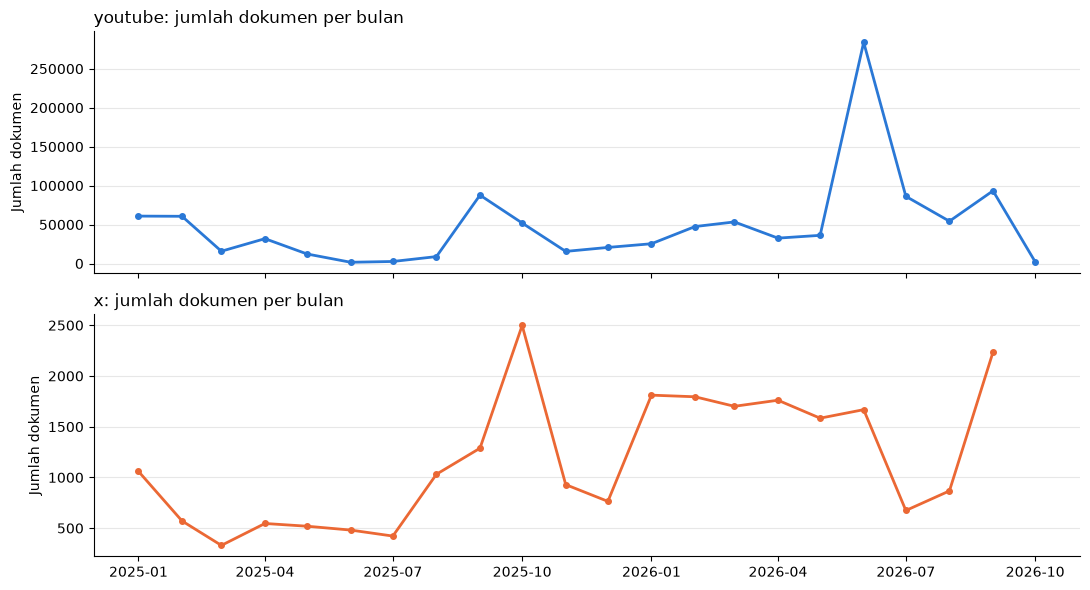

In [40]:
merged["month"] = pd.to_datetime(merged["published_at_utc"]).dt.tz_localize(None).dt.to_period("M").dt.to_timestamp()
monthly = merged.groupby(["platform", "month"]).size().rename("n_docs").reset_index()

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for ax, platform in zip(axes, PLATFORMS):
    data = monthly[monthly["platform"] == platform]
    ax.plot(data["month"], data["n_docs"], color=PLATFORM_COLORS[platform], linewidth=2, marker="o", markersize=4)
    ax.set_title(f"{platform}: jumlah dokumen per bulan", loc="left")
    ax.set_ylabel("Jumlah dokumen")
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
save_figure("monthly_docs_per_platform")

## 6.3. Ringkasan Flag per Platform

In [41]:
flag_counts = merged.groupby("platform")[FLAG_COLUMNS].sum().T[PLATFORMS]
flag_pct = (merged.groupby("platform")[FLAG_COLUMNS].mean().T[PLATFORMS] * 100).round(2)
display(flag_counts.join(flag_pct, lsuffix="_n", rsuffix="_%"))

platform,youtube_n,x_n,youtube_%,x_%
is_suspected_spam,2357,0,0.22,0.00
is_repeated_text,69737,1012,6.43,4.12
mentions_mbg,288895,24187,26.62,98.58
mentions_food_safety,88383,14833,8.14,60.46
context_mentions_mbg,1082877,17435,99.77,71.06
is_relevant_candidate,88135,14731,8.12,60.04


## 6.4. Sebaran Provinsi pada Dokumen Relevan

Menghitung provinsi yang disebut pada dokumen **kandidat relevan dan bukan spam**. Karena jumlah dokumen kedua platform berbeda jauh, perbandingan memakai **persentase** terhadap total penyebutan provinsi di masing-masing platform. Satu dokumen yang menyebut beberapa provinsi dihitung di setiap provinsi tersebut.

In [42]:
relevant = merged[merged["is_relevant_candidate"] & ~merged["is_suspected_spam"] & (merged["province"] != "")]
province_mentions = (relevant.assign(province=relevant["province"].str.split("; "))
                     .explode("province")
                     .groupby(["province", "platform"]).size().unstack(fill_value=0)
                     .reindex(columns=PLATFORMS, fill_value=0))
province_share = (province_mentions / province_mentions.sum() * 100).round(1)
province_table = province_mentions.join(province_share, lsuffix="_n", rsuffix="_%")
province_table = province_table.sort_values("youtube_n", ascending=False)
save_csv(province_table.reset_index(), OUTPUT_DIR / "relevant_docs_per_province.csv")
display(province_table.head(15))

platform,youtube_n,x_n,youtube_%,x_%
province,,,,
Jawa Barat,1325,766,22.7,11.1
Jawa Tengah,888,881,15.2,12.7
Jawa Timur,817,685,14.0,9.9
DKI Jakarta,651,375,11.1,5.4
Sumatera Utara,366,294,6.3,4.2
Papua,234,172,4.0,2.5
Daerah Istimewa Yogyakarta,190,375,3.3,5.4
Banten,117,257,2.0,3.7
Sulawesi Selatan,111,188,1.9,2.7


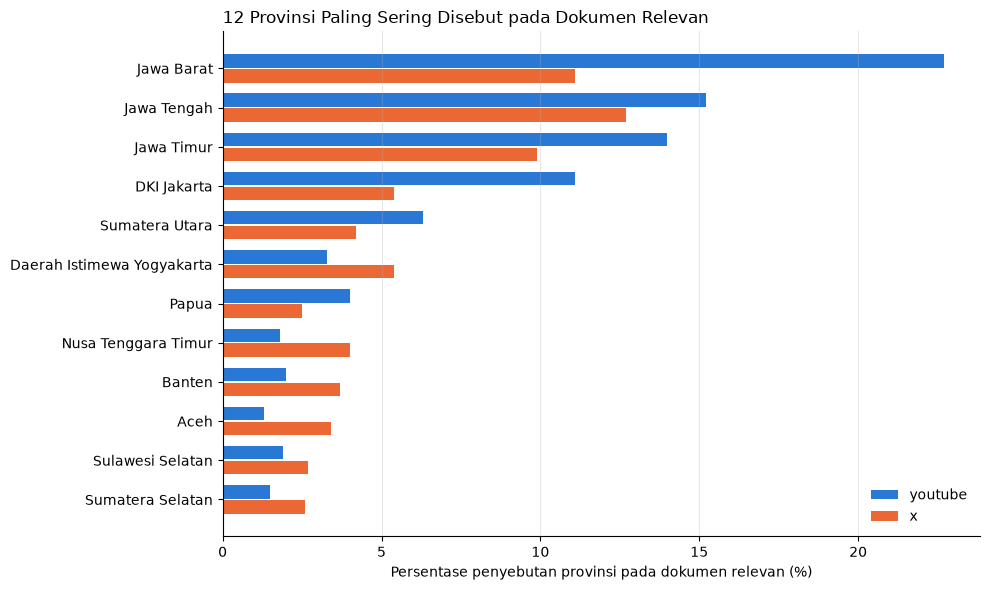

In [43]:
top_provinces = province_mentions.sum(axis=1).sort_values(ascending=False).head(12).index[::-1]
plot_data = province_share.loc[top_provinces]

fig, ax = plt.subplots(figsize=(10, 6))
bar_height = 0.38
positions = range(len(plot_data))
for offset, platform in [(bar_height / 2, "youtube"), (-bar_height / 2, "x")]:
    ax.barh([p + offset for p in positions], plot_data[platform], height=bar_height * 0.9,
            color=PLATFORM_COLORS[platform], label=platform)
ax.set_yticks(list(positions))
ax.set_yticklabels(plot_data.index)
ax.set_xlabel("Persentase penyebutan provinsi pada dokumen relevan (%)")
ax.set_title("12 Provinsi Paling Sering Disebut pada Dokumen Relevan", loc="left")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="x", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
save_figure("relevant_province_share")

## 6.5. Ringkasan Dataset Gabungan

In [44]:
summary_rows = []
for platform in PLATFORMS:
    part = merged[merged["platform"] == platform]
    published = pd.to_datetime(part["published_at_utc"])
    summary_rows.append({
        "platform": platform,
        "n_docs": len(part),
        "n_unique_authors": part.loc[part["author_hash"] != "", "author_hash"].nunique(),
        "first_published_utc": published.min(),
        "last_published_utc": published.max(),
        "pct_with_location": round((part["province"] != "").mean() * 100, 1),
        "pct_relevant_candidate": round(part["is_relevant_candidate"].mean() * 100, 1),
        "pct_suspected_spam": round(part["is_suspected_spam"].mean() * 100, 2),
    })
merge_summary = pd.DataFrame(summary_rows).set_index("platform")
save_csv(merge_summary.reset_index(), OUTPUT_DIR / "merge_summary.csv")
display(merge_summary.T)

platform,youtube,x
n_docs,1085353,24535
n_unique_authors,420072,7968
first_published_utc,2025-01-05 22:34:42+00:00,2025-01-01 07:56:38+00:00
last_published_utc,2026-10-24 00:55:09+00:00,2026-09-29 23:02:39+00:00
pct_with_location,2.7,23.1
pct_relevant_candidate,8.1,60.0
pct_suspected_spam,0.22,0.0


# 7. Catatan dan Keterbatasan

* **Kelengkapan data YouTube.** Selama `youtube_collection_complete` masih `False` (bagian 2.1), dataset gabungan bersifat sementara dan notebook ini perlu dijalankan ulang setelah pengumpulan YouTube selesai.
* **Cara pengumpulan berbeda.** Query X sudah spesifik keamanan pangan (keracunan, basi, bakteri, dan lain-lain), sedangkan YouTube mengambil seluruh video MBG lalu semua comment-nya. Akibatnya, persentase dokumen relevan di X jauh lebih tinggi **karena desain pengumpulan**, bukan karena publik X lebih peduli. Perbandingan antarplatform sebaiknya dilakukan pada subset `is_relevant_candidate`.
* **Jenis dokumen tidak setara.** Video YouTube adalah konten media/BGN, sedangkan comment/reply YouTube dan unggahan X adalah suara publik (walaupun akun media juga dapat mengunggah di X). Untuk RQ3 (kekhawatiran publik), video sebaiknya dipisahkan dari comment.
* **Ekstraksi lokasi berbeda.** Kedua *pipeline* memakai kamus wilayah Kemendagri, tetapi aturan nama ambigu dan aliasnya berbeda. Nama provinsi sudah diseragamkan, tetapi perbandingan antarplatform sebaiknya memakai proporsi, bukan jumlah absolut.
* **Engagement tidak sebanding.** *Like* dan *reply* di YouTube dan X memiliki skala dan perilaku pengguna yang berbeda, sehingga tidak dijumlahkan atau dibandingkan langsung.
* **Flag berbasis kata kunci.** `is_relevant_candidate` dan `is_suspected_spam` adalah penanda awal berbasis aturan. Daftar nama situs judi disusun dari spam YouTube, sehingga spam X dengan nama situs lain yang ditulis biasa dapat lolos.
* **Etika.** Dataset gabungan hanya memuat pseudonim penulis (`author_hash`) dan tautan tanpa *handle* akun. File `mbg_merged.csv` tidak dipublikasikan; yang diunggah ke repositori hanya metadata dan tabel ringkasan.